In [9]:
import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objects as go
import warnings
warnings.filterwarnings('ignore')

df_customers = pd.read_csv('data/olist_customers_dataset.csv')
df_orders = pd.read_csv('data/olist_orders_dataset.csv')
df_products = pd.read_csv('data/olist_products_dataset.csv')
df_order_items = pd.read_csv('data/olist_order_items_dataset.csv')
df_order_payments = pd.read_csv('data/olist_order_payments_dataset.csv')
df_order_reviews = pd.read_csv('data/olist_order_reviews_dataset.csv')
df_sellers = pd.read_csv('data/olist_sellers_dataset.csv')
df_category_translation = pd.read_csv('data/product_category_name_translation.csv')

print(f"Customers: {len(df_customers):,} rows")
print(f"Orders: {len(df_orders):,} rows")
print(f"Products: {len(df_products):,} rows")
print(f"Order Items: {len(df_order_items):,} rows")


Customers: 99,441 rows
Orders: 99,441 rows
Products: 32,951 rows
Order Items: 112,650 rows


In [10]:
def data_quality(df, name):
    total = len(df)
    missing = df.isnull().sum().sum()
    duplicates = df.duplicated().sum()
    print(f"{name}: {total:,} rows | Missing: {missing} ({missing/total*100:.1f}%) | Duplicates: {duplicates}")

data_quality(df_customers, "Customers")
data_quality(df_orders, "Orders")
data_quality(df_products, "Products")
data_quality(df_order_items, "Order Items")
data_quality(df_order_payments, "Order Payments")
data_quality(df_order_reviews, "Order Reviews")

Customers: 99,441 rows | Missing: 0 (0.0%) | Duplicates: 0
Orders: 99,441 rows | Missing: 4908 (4.9%) | Duplicates: 0
Products: 32,951 rows | Missing: 2448 (7.4%) | Duplicates: 0
Order Items: 112,650 rows | Missing: 0 (0.0%) | Duplicates: 0
Order Payments: 103,886 rows | Missing: 0 (0.0%) | Duplicates: 0
Order Reviews: 99,224 rows | Missing: 145903 (147.0%) | Duplicates: 0


In [11]:
date_cols = ['order_purchase_timestamp', 'order_approved_at', 
             'order_delivered_carrier_date', 'order_delivered_customer_date',
             'order_estimated_delivery_date']

for col in date_cols:
    df_orders[col] = pd.to_datetime(df_orders[col], errors='coerce')

df_orders_delivered = df_orders[df_orders['order_status'] == 'delivered'].copy()
print(f"Delivered orders: {len(df_orders_delivered):,} / {len(df_orders):,} total ({len(df_orders_delivered)/len(df_orders)*100:.1f}%)")

Delivered orders: 96,478 / 99,441 total (97.0%)


In [12]:
df_products = df_products.merge(df_category_translation, on='product_category_name', how='left')

df_sales = df_orders_delivered.merge(df_order_items, on='order_id', how='left')
df_sales = df_sales.merge(df_products[['product_id', 'product_category_name', 'product_category_name_english']], 
                          on='product_id', how='left')
df_sales = df_sales.merge(df_customers, on='customer_id', how='left')
df_sales = df_sales.merge(df_order_payments[['order_id', 'payment_value']], on='order_id', how='left')

df_sales['revenue'] = df_sales['price']
print(f"Sales table: {len(df_sales):,} rows | {len(df_sales.columns)} columns")

Sales table: 115,038 rows | 22 columns


In [13]:
total_revenue = df_sales['price'].sum()
total_orders = df_sales['order_id'].nunique()
avg_order_value = df_sales.groupby('order_id')['price'].sum().mean()
total_customers = df_sales['customer_id'].nunique()
avg_orders_per_customer = total_orders / total_customers

print(f"Total Revenue: R$ {total_revenue:,.2f}")
print(f"Total Orders: {total_orders:,}")
print(f"Average Order Value: R$ {avg_order_value:.2f}")
print(f"Total Customers: {total_customers:,}")
print(f"Orders per Customer: {avg_orders_per_customer:.2f}")

top_categories = df_sales.groupby('product_category_name_english')['order_id'].count().sort_values(ascending=False).head(5)
print(f"\nTop 5 Categories:\n{top_categories}")

Total Revenue: R$ 13,813,963.68
Total Orders: 96,478
Average Order Value: R$ 143.18
Total Customers: 96,478
Orders per Customer: 1.00

Top 5 Categories:
product_category_name_english
bed_bath_table           11650
health_beauty             9762
sports_leisure            8733
furniture_decor           8557
computers_accessories     7898
Name: order_id, dtype: int64


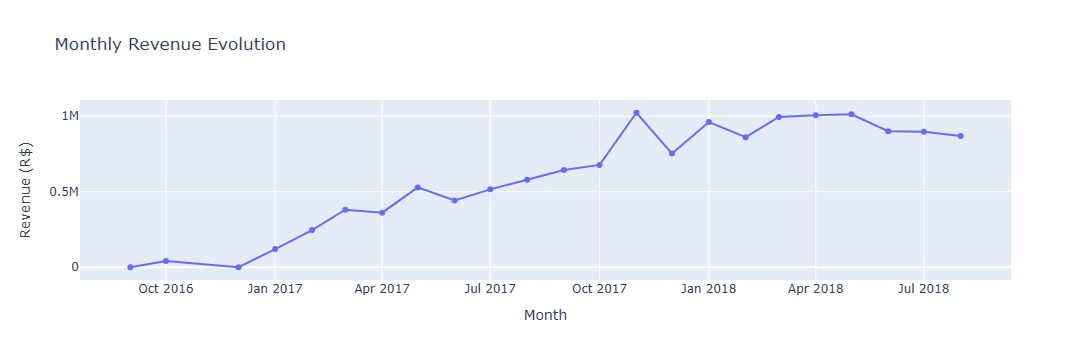

In [14]:
df_sales['order_month'] = df_sales['order_purchase_timestamp'].dt.to_period('M')
monthly_revenue = df_sales.groupby('order_month')['price'].sum().reset_index()
monthly_revenue['order_month'] = monthly_revenue['order_month'].astype(str)

fig1 = px.line(monthly_revenue, x='order_month', y='price', 
               title='Monthly Revenue Evolution', markers=True)
fig1.update_layout(xaxis_title='Month', yaxis_title='Revenue (R$)')
fig1.show()

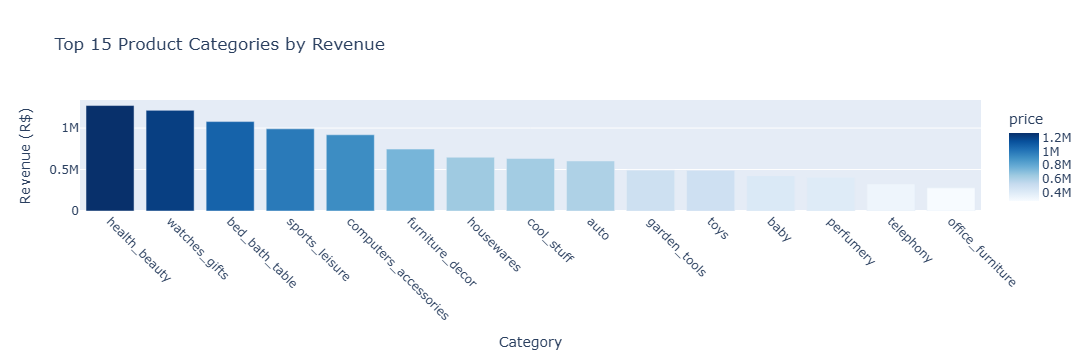

In [15]:
category_revenue = df_sales.groupby('product_category_name_english')['price'].sum().sort_values(ascending=False).head(15).reset_index()

fig2 = px.bar(category_revenue, x='product_category_name_english', y='price',
              title='Top 15 Product Categories by Revenue',
              color='price', color_continuous_scale='Blues')
fig2.update_layout(xaxis_title='Category', yaxis_title='Revenue (R$)', xaxis_tickangle=45)
fig2.show()

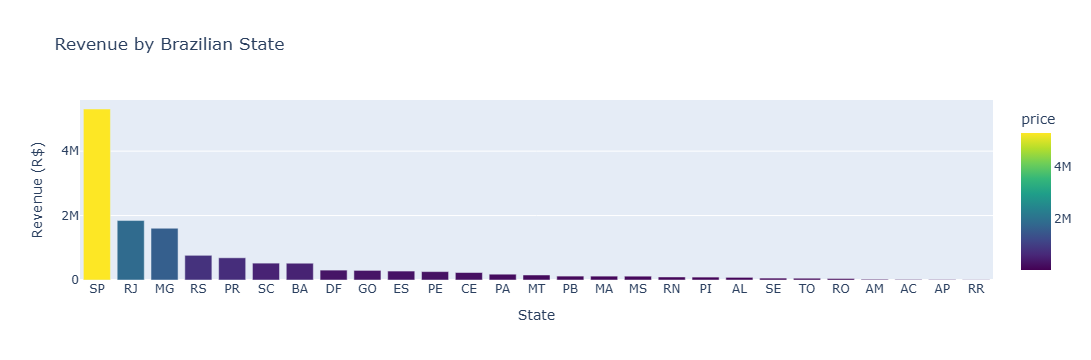

In [16]:
state_revenue = df_sales.groupby('customer_state')['price'].sum().sort_values(ascending=False).reset_index()

fig3 = px.bar(state_revenue, x='customer_state', y='price',
              title='Revenue by Brazilian State',
              color='price', color_continuous_scale='Viridis')
fig3.update_layout(xaxis_title='State', yaxis_title='Revenue (R$)')
fig3.show()

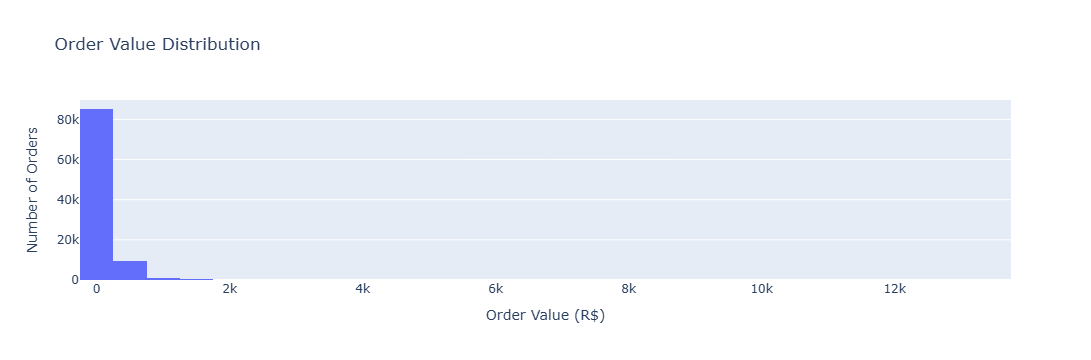

In [17]:
order_values = df_sales.groupby('order_id')['price'].sum()

fig4 = px.histogram(order_values, x='price', nbins=50,
                    title='Order Value Distribution')
fig4.update_layout(xaxis_title='Order Value (R$)', yaxis_title='Number of Orders')
fig4.show()

In [18]:
df_dashboard = df_sales.groupby(['order_id', 'customer_id', 'customer_state', 
                                  'product_category_name_english', 'order_purchase_timestamp']).agg({
    'price': 'sum',
    'order_status': 'first'
}).reset_index()

df_dashboard.to_csv('data/df_dashboard_ready.csv', index=False)
print(f"Dashboard data saved: {len(df_dashboard):,} rows")

Dashboard data saved: 95,864 rows
